In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import accuracy_score, confusion_matrix, precision_recall_curve, average_precision_score
import pickle

In [2]:
df = pd.read_csv('final_data/cleaned_2019.csv')
df = df[[i for i in df.columns if 'original' not in i]]
df = df[[i for i in df.columns if 'qa' not in i]]
df = df[[i for i in df.columns if 'income' not in i]]
df = df.iloc[:, :-4]
df = df.drop(columns=['fd_label', 'label_status', 'label_reason'])

# adding a leading zero to tract_id to match geoid
df['tract_id'] = df['tract_id'].apply(lambda x: f'0{x}')

df.head()

,tract_id,State,County,meta_dataset_version,meta_population_census_year,meta_tract_vintage,clean__Urban,clean__population_total,clean__occupied_housing_units_total,clean__GroupQuartersFlag,...,clean__PovertyRate,clean__MedianFamilyIncome,clean__TractLOWI,clean__TractHUNV,clean__TractSNAP,clean__LATracts_half,clean__LATracts1,clean__LATractsVehicle_20,clean__low_access_population_1_20,FD_2
0,01001020100,Alabama,Autauga County,2019,2010,2010,1.0,1912.0,693.0,0.0,...,11.3,81250.0,455.0,6.0,102.0,1.0,1.0,0.0,1896.0,1
1,01001020200,Alabama,Autauga County,2019,2010,2010,1.0,2170.0,743.0,0.0,...,17.9,49000.0,802.0,89.0,156.0,1.0,1.0,0.0,1261.0,1
2,01001020300,Alabama,Autauga County,2019,2010,2010,1.0,3373.0,1256.0,0.0,...,15.0,62609.0,1306.0,99.0,172.0,1.0,1.0,0.0,1552.0,1
3,01001020400,Alabama,Autauga County,2019,2010,2010,1.0,4386.0,1722.0,0.0,...,2.8,70607.0,922.0,21.0,98.0,1.0,1.0,0.0,1363.0,1
4,01001020500,Alabama,Autauga County,2019,2010,2010,1.0,10766.0,4082.0,0.0,...,15.2,96334.0,2242.0,230.0,339.0,1.0,1.0,1.0,2643.0,1


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 72531 entries, 0 to 72530
Data columns (total 32 columns):
 #   Column                               Non-Null Count  Dtype  
---  ------                               --------------  -----  
 0   tract_id                             72531 non-null  int64  
 1   State                                72531 non-null  object 
 2   County                               72531 non-null  object 
 3   meta_dataset_version                 72531 non-null  int64  
 4   meta_population_census_year          72531 non-null  int64  
 5   meta_tract_vintage                   72531 non-null  int64  
 6   clean__Urban                         72531 non-null  float64
 7   clean__population_total              72531 non-null  float64
 8   clean__occupied_housing_units_total  72531 non-null  float64
 9   clean__GroupQuartersFlag             72531 non-null  float64
 10  clean__NUMGQTRS                      72506 non-null  float64
 11  clean__PCTGQTRS             

response variable, 'food_desert', binary variable (1/0) \
to qualify as a food desert tract, at least 33% of the tract's population or a minimum of 500 people in the tract must have low access to a supermarket or large grocery store \
using variable, low_access_population_1_20, to define food desert value. this variable lists the population count beyond 1 mile for urban areas or 20 miles for rural areas from supermarket

**Using FD_2 as the binary variable to indicate food desert status**

In [ ]:
# df['food_desert'] = np.where((df['clean__low_access_population_1_20'] / df['clean__population_total'] >= 0.33) | (df['clean__low_access_population_1_20'] >= 500), 1, 0)
# df.head()

,tract_id,State,County,meta_dataset_version,meta_population_census_year,meta_tract_vintage,clean__Urban,clean__population_total,clean__occupied_housing_units_total,clean__GroupQuartersFlag,...,clean__PovertyRate,clean__MedianFamilyIncome,clean__TractLOWI,clean__TractHUNV,clean__TractSNAP,clean__LATracts_half,clean__LATracts1,clean__LATractsVehicle_20,clean__low_access_population_1_20,food_desert
0,1001020100,Alabama,Autauga County,2019,2010,2010,1.0,1912.0,693.0,0.0,...,11.3,81250.0,455.0,6.0,102.0,1.0,1.0,0.0,1896.0,1
1,1001020200,Alabama,Autauga County,2019,2010,2010,1.0,2170.0,743.0,0.0,...,17.9,49000.0,802.0,89.0,156.0,1.0,1.0,0.0,1261.0,1
2,1001020300,Alabama,Autauga County,2019,2010,2010,1.0,3373.0,1256.0,0.0,...,15.0,62609.0,1306.0,99.0,172.0,1.0,1.0,0.0,1552.0,1
3,1001020400,Alabama,Autauga County,2019,2010,2010,1.0,4386.0,1722.0,0.0,...,2.8,70607.0,922.0,21.0,98.0,1.0,1.0,0.0,1363.0,1
4,1001020500,Alabama,Autauga County,2019,2010,2010,1.0,10766.0,4082.0,0.0,...,15.2,96334.0,2242.0,230.0,339.0,1.0,1.0,1.0,2643.0,1


In [4]:
trainData, testData = train_test_split(
    df,
    test_size=0.2,
    random_state=42,
    stratify=df['FD_2']
)

## Modeling on Train Data

In [5]:
trainData.isna().sum()

tract_id                                   0
State                                      0
County                                     0
meta_dataset_version                       0
meta_population_census_year                0
meta_tract_vintage                         0
clean__Urban                               0
clean__population_total                    0
clean__occupied_housing_units_total        0
clean__GroupQuartersFlag                   0
clean__NUMGQTRS                           22
clean__PCTGQTRS                           22
clean__TractKids                           4
clean__TractSeniors                        4
clean__TractWhite                          4
clean__TractBlack                          4
clean__TractAsian                          4
clean__TractNHOPI                          4
clean__TractAIAN                           4
clean__TractOMultir                        4
clean__TractHispanic                       4
clean__LowIncomeTracts                     0
clean__Pov

In [6]:
trainData["clean__NUMGQTRS"] = trainData["clean__NUMGQTRS"].fillna(trainData["clean__NUMGQTRS"].median())
trainData["clean__PCTGQTRS"] = trainData["clean__PCTGQTRS"].fillna(trainData["clean__PCTGQTRS"].median())

trainData["clean__TractKids"] = trainData["clean__TractKids"].fillna(trainData["clean__TractKids"].median())
trainData["clean__TractSeniors"] = trainData["clean__TractSeniors"].fillna(trainData["clean__TractSeniors"].median())
trainData["clean__TractWhite"] = trainData["clean__TractWhite"].fillna(trainData["clean__TractWhite"].median())
trainData["clean__TractBlack"] = trainData["clean__TractBlack"].fillna(trainData["clean__TractBlack"].median())
trainData["clean__TractAsian"] = trainData["clean__TractAsian"].fillna(trainData["clean__TractAsian"].median())
trainData["clean__TractNHOPI"] = trainData["clean__TractNHOPI"].fillna(trainData["clean__TractNHOPI"].median())
trainData["clean__TractAIAN"] = trainData["clean__TractAIAN"].fillna(trainData["clean__TractAIAN"].median())
trainData["clean__TractOMultir"] = trainData["clean__TractOMultir"].fillna(trainData["clean__TractOMultir"].median())
trainData["clean__TractHispanic"] = trainData["clean__TractHispanic"].fillna(trainData["clean__TractHispanic"].median())

trainData["clean__PovertyRate"] = trainData["clean__PovertyRate"].fillna(trainData["clean__PovertyRate"].median())
trainData["clean__MedianFamilyIncome"] = trainData["clean__MedianFamilyIncome"].fillna(trainData["clean__MedianFamilyIncome"].median())

trainData["clean__TractLOWI"] = trainData["clean__TractLOWI"].fillna(trainData["clean__TractLOWI"].median())
trainData["clean__TractHUNV"] = trainData["clean__TractHUNV"].fillna(trainData["clean__TractHUNV"].median())
trainData["clean__TractSNAP"] = trainData["clean__TractSNAP"].fillna(trainData["clean__TractSNAP"].median())

trainData["clean__low_access_population_1_20"] = trainData["clean__low_access_population_1_20"].fillna(0)

In [7]:
model = smf.logit(formula = 'FD_2 ~ clean__Urban + clean__population_total + clean__occupied_housing_units_total + clean__GroupQuartersFlag \
                            + clean__NUMGQTRS + clean__PCTGQTRS + clean__LowIncomeTracts + clean__PovertyRate + clean__MedianFamilyIncome + clean__TractLOWI \
                            + clean__TractKids + clean__TractSeniors + clean__TractWhite + clean__TractBlack + clean__TractAsian + clean__TractNHOPI + clean__TractAIAN \
                            + clean__TractOMultir + clean__TractHispanic + clean__TractHUNV + clean__TractSNAP + clean__LATracts_half + clean__LATracts1 \
                            + clean__LATractsVehicle_20',
                  data = trainData).fit()
print(model.summary())

         Current function value: 0.005915
         Iterations: 35
                           Logit Regression Results                           
Dep. Variable:                   FD_2   No. Observations:                58024
Model:                          Logit   Df Residuals:                    57999
Method:                           MLE   Df Model:                           24
Date:                Mon, 02 Nov 2026   Pseudo R-squ.:                  0.9908
Time:                        17:58:40   Log-Likelihood:                -343.23
converged:                      False   LL-Null:                       -37221.
Covariance Type:            nonrobust   LLR p-value:                     0.000
                                          coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------------------------
Intercept                             -15.9332     13.336     -1.195      0.232     -42.071   

/home/cindy/anaconda3/envs/analytics/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


In [8]:
# model2: variable selection; dropping features with high p-values
model2 = smf.logit(formula = 'FD_2 ~ clean__occupied_housing_units_total \
                            + clean__NUMGQTRS + clean__PovertyRate + clean__MedianFamilyIncome + clean__TractLOWI + clean__TractKids \
                            + clean__TractHispanic + clean__TractHUNV + clean__TractSNAP \
                            + clean__LATractsVehicle_20',
                  data = trainData).fit()
print(model2.summary())

Optimization terminated successfully.
         Current function value: 0.562034
         Iterations 7
                           Logit Regression Results                           
Dep. Variable:                   FD_2   No. Observations:                58024
Model:                          Logit   Df Residuals:                    58013
Method:                           MLE   Df Model:                           10
Date:                Mon, 02 Nov 2026   Pseudo R-squ.:                  0.1238
Time:                        17:58:45   Log-Likelihood:                -32611.
converged:                       True   LL-Null:                       -37221.
Covariance Type:            nonrobust   LLR p-value:                     0.000
                                          coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------------------------
Intercept                              -2.1141      0.049 

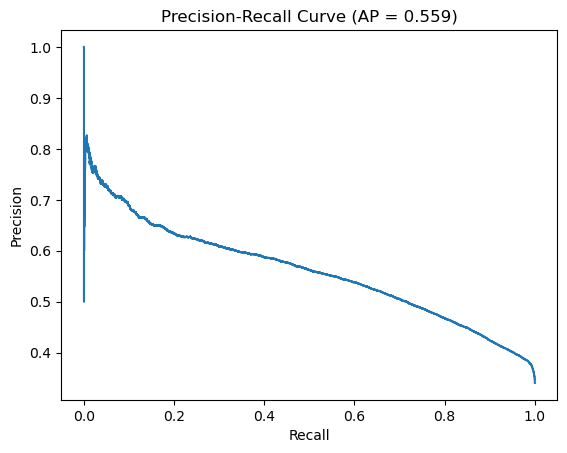

In [9]:
preds2 = model2.predict(trainData)

precision2, recall2, thresholds2 = precision_recall_curve(trainData['FD_2'], preds2)
ap2 = average_precision_score(trainData['FD_2'], preds2)

plt.plot(recall2, precision2)
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title(f"Precision-Recall Curve (AP = {ap2:.3f})")
plt.show()

## Test Data Prediction

In [10]:
testData.isna().sum()

tract_id                                  0
State                                     0
County                                    0
meta_dataset_version                      0
meta_population_census_year               0
meta_tract_vintage                        0
clean__Urban                              0
clean__population_total                   0
clean__occupied_housing_units_total       0
clean__GroupQuartersFlag                  0
clean__NUMGQTRS                           3
clean__PCTGQTRS                           3
clean__TractKids                          0
clean__TractSeniors                       0
clean__TractWhite                         0
clean__TractBlack                         0
clean__TractAsian                         0
clean__TractNHOPI                         0
clean__TractAIAN                          0
clean__TractOMultir                       0
clean__TractHispanic                      0
clean__LowIncomeTracts                    0
clean__PovertyRate              

In [11]:
testData["clean__NUMGQTRS"] = testData["clean__NUMGQTRS"].fillna(testData["clean__NUMGQTRS"].median())
testData["clean__PCTGQTRS"] = testData["clean__PCTGQTRS"].fillna(testData["clean__PCTGQTRS"].median())

# testData["clean__TractKids"] = testData["clean__TractKids"].fillna(testData["clean__TractKids"].median())
# testData["clean__TractSeniors"] = testData["clean__TractSeniors"].fillna(testData["clean__TractSeniors"].median())
# testData["clean__TractWhite"] = testData["clean__TractWhite"].fillna(testData["clean__TractWhite"].median())
# testData["clean__TractBlack"] = testData["clean__TractBlack"].fillna(testData["clean__TractBlack"].median())
# testData["clean__TractAsian"] = testData["clean__TractAsian"].fillna(testData["clean__TractAsian"].median())
# testData["clean__TractNHOPI"] = testData["clean__TractNHOPI"].fillna(testData["clean__TractNHOPI"].median())
# testData["clean__TractAIAN"] = testData["clean__TractAIAN"].fillna(testData["clean__TractAIAN"].median())
# testData["clean__TractOMultir"] = testData["clean__TractOMultir"].fillna(testData["clean__TractOMultir"].median())
# testData["clean__TractHispanic"] = testData["clean__TractHispanic"].fillna(testData["clean__TractHispanic"].median())

# testData["clean__PovertyRate"] = testData["clean__PovertyRate"].fillna(testData["clean__PovertyRate"].median())
testData["clean__MedianFamilyIncome"] = testData["clean__MedianFamilyIncome"].fillna(testData["clean__MedianFamilyIncome"].median())

# testData["clean__TractLOWI"] = testData["clean__TractLOWI"].fillna(testData["clean__TractLOWI"].median())
# testData["clean__TractHUNV"] = testData["clean__TractHUNV"].fillna(testData["clean__TractHUNV"].median())
# testData["clean__TractSNAP"] = testData["clean__TractSNAP"].fillna(testData["clean__TractSNAP"].median())

testData["clean__low_access_population_1_20"] = testData["clean__low_access_population_1_20"].fillna(0)

In [12]:
preds_test = model2.predict(testData)

thresholds = np.arange(0.05, 0.90, 0.05)

acc = pd.DataFrame({
    "threshold": thresholds.round(2),
    "accuracy": [accuracy_score(testData['FD_2'], (preds_test >= t).astype(int)) for t in thresholds],
})

best_threshold = acc.loc[acc["accuracy"].idxmax()]
print(best_threshold)

threshold    0.450000
accuracy     0.702971
Name: 8, dtype: float64


In [13]:
testData["pred_prob"] = preds_test
testData["pred_class"] = (preds_test >= 0.45).astype(int)

testData["risk"] = pd.cut(
    testData["pred_prob"],
    bins=[0, 0.33, 0.67, 1],
    labels=["low-risk", "medium-risk", "high-risk"],
    include_lowest=True
)

print(testData["risk"].value_counts())

risk
low-risk       7954
medium-risk    5756
high-risk       797
Name: count, dtype: int64


In [14]:
y_true_test = testData["FD_2"]
y_pred_test = testData["pred_class"]

print("Accuracy :", accuracy_score(y_true_test, y_pred_test))
print(confusion_matrix(y_true_test, y_pred_test)) # rows = actual, cols = predicted

Accuracy : 0.7029709795271248
[[8014 1551]
 [2758 2184]]


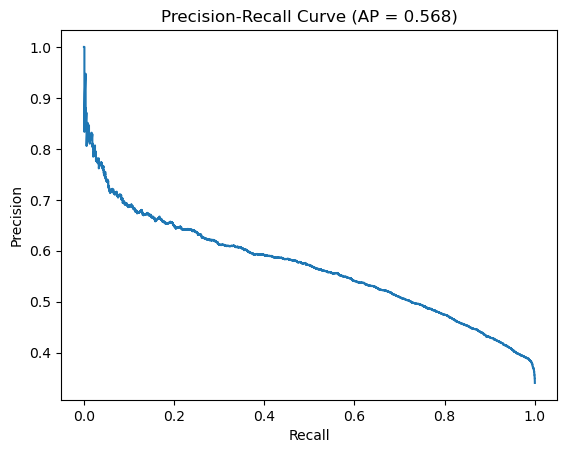

In [15]:
precision_test, recall_test, thresholds_test = precision_recall_curve(testData['FD_2'], preds_test)
ap_test = average_precision_score(testData['FD_2'], preds_test)

plt.plot(recall_test, precision_test)
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title(f"Precision-Recall Curve (AP = {ap_test:.3f})")
plt.show()

## Training model on full data

In [16]:
df.isna().sum()

tract_id                                   0
State                                      0
County                                     0
meta_dataset_version                       0
meta_population_census_year                0
meta_tract_vintage                         0
clean__Urban                               0
clean__population_total                    0
clean__occupied_housing_units_total        0
clean__GroupQuartersFlag                   0
clean__NUMGQTRS                           25
clean__PCTGQTRS                           25
clean__TractKids                           4
clean__TractSeniors                        4
clean__TractWhite                          4
clean__TractBlack                          4
clean__TractAsian                          4
clean__TractNHOPI                          4
clean__TractAIAN                           4
clean__TractOMultir                        4
clean__TractHispanic                       4
clean__LowIncomeTracts                     0
clean__Pov

In [17]:
df["clean__NUMGQTRS"] = df["clean__NUMGQTRS"].fillna(df["clean__NUMGQTRS"].median())
df["clean__PCTGQTRS"] = df["clean__PCTGQTRS"].fillna(df["clean__PCTGQTRS"].median())

df["clean__TractKids"] = df["clean__TractKids"].fillna(df["clean__TractKids"].median())
df["clean__TractSeniors"] = df["clean__TractSeniors"].fillna(df["clean__TractSeniors"].median())
df["clean__TractWhite"] = df["clean__TractWhite"].fillna(df["clean__TractWhite"].median())
df["clean__TractBlack"] = df["clean__TractBlack"].fillna(df["clean__TractBlack"].median())
df["clean__TractAsian"] = df["clean__TractAsian"].fillna(df["clean__TractAsian"].median())
df["clean__TractNHOPI"] = df["clean__TractNHOPI"].fillna(df["clean__TractNHOPI"].median())
df["clean__TractAIAN"] = df["clean__TractAIAN"].fillna(df["clean__TractAIAN"].median())
df["clean__TractOMultir"] = df["clean__TractOMultir"].fillna(df["clean__TractOMultir"].median())
df["clean__TractHispanic"] = df["clean__TractHispanic"].fillna(df["clean__TractHispanic"].median())

df["clean__PovertyRate"] = df["clean__PovertyRate"].fillna(df["clean__PovertyRate"].median())
df["clean__MedianFamilyIncome"] = df["clean__MedianFamilyIncome"].fillna(df["clean__MedianFamilyIncome"].median())

df["clean__TractLOWI"] = df["clean__TractLOWI"].fillna(df["clean__TractLOWI"].median())
df["clean__TractHUNV"] = df["clean__TractHUNV"].fillna(df["clean__TractHUNV"].median())
df["clean__TractSNAP"] = df["clean__TractSNAP"].fillna(df["clean__TractSNAP"].median())

df["clean__low_access_population_1_20"] = df["clean__low_access_population_1_20"].fillna(0)

In [19]:
full_model = smf.logit(formula = 'FD_2 ~ clean__occupied_housing_units_total \
                            + clean__NUMGQTRS + clean__PovertyRate + clean__MedianFamilyIncome + clean__TractLOWI + clean__TractKids \
                            + clean__TractHispanic + clean__TractHUNV + clean__TractSNAP \
                            + clean__LATractsVehicle_20',
                  data = df).fit()
print(full_model.summary())

Optimization terminated successfully.
         Current function value: 0.560963
         Iterations 7
                           Logit Regression Results                           
Dep. Variable:                   FD_2   No. Observations:                72531
Model:                          Logit   Df Residuals:                    72520
Method:                           MLE   Df Model:                           10
Date:                Mon, 02 Nov 2026   Pseudo R-squ.:                  0.1255
Time:                        18:02:42   Log-Likelihood:                -40687.
converged:                       True   LL-Null:                       -46527.
Covariance Type:            nonrobust   LLR p-value:                     0.000
                                          coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------------------------
Intercept                              -2.0959      0.043 

In [20]:
# output model to pickle file
with open('log_reg_model.pkl', 'wb') as f:
    pickle.dump(full_model, f)